# TPI Análisis de Datos - Telco Customer Churn

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andyargg/tpi-analisis-de-datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)

Introducción al Análisis de Datos - UTN Avellaneda - Div. 143
Profe: Zotti, Enzo Martín
Integrantes: Matias Asenjo, Damian Bello, Andres Arguindegui y J. Zubini

En este trabajo usamos el dataset Telco Customer Churn para ver por qué los clientes de una empresa
de telefonía/internet se dan de baja.

## 1. Los datos

### 1.1 Librerías y carga

Usamos pandas y numpy para trabajar con los datos, y matplotlib y seaborn para los gráficos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)  # para que muestre todas las columnas

El csv lo leemos directo desde el repo de github, asi se puede correr en Colab sin subir nada.

In [ ]:
url = "https://raw.githubusercontent.com/andyargg/tpi-analisis-de-datos/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("filas:", df.shape[0])
print("columnas:", df.shape[1])

filas: 7043
columnas: 21


### 1.2 Primer vistazo

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 1.3 Problema e hipótesis

La empresa está perdiendo clientes y queremos entender qué tienen en común los que se van, para que
puedan hacer algo para retenerlos antes de que cancelen.

La variable que nos interesa es **Churn** (Yes = se dio de baja, No = sigue siendo cliente). Veamos
cuántos hay de cada uno:

In [ ]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Se fue más o menos el 26% de los clientes, o sea 1 de cada 4. Hay muchos más "No" que "Yes", así que
cuando comparemos grupos vamos a usar porcentajes y no cantidades.

Hipótesis que queremos comprobar:

- H1: los que tienen contrato mes a mes se van más que los de 1 o 2 años (se pueden ir cuando quieren).
- H2: los clientes nuevos se van más que los que hace mucho que están.
- H3: los que pagan más por mes se van más.
- H4: los que pagan con cheque se van más que los que tienen débito automático.

### 1.4 Tipo de dataset y tipos de variables

El dataset es **estructurado** porque es una tabla: cada fila es un cliente y todas las filas tienen
las mismas columnas. No es semi-estructurado (tipo JSON) ni no estructurado (texto libre, imágenes, etc).

Ahora clasificamos cada variable (nominal, ordinal, discreta o continua) y lo comparamos con el tipo
que le puso pandas.

In [ ]:
tipos = {
    "customerID": "identificador",
    "gender": "cualitativa nominal",
    "SeniorCitizen": "cualitativa nominal",
    "Partner": "cualitativa nominal",
    "Dependents": "cualitativa nominal",
    "tenure": "cuantitativa discreta",
    "PhoneService": "cualitativa nominal",
    "MultipleLines": "cualitativa nominal",
    "InternetService": "cualitativa nominal",
    "OnlineSecurity": "cualitativa nominal",
    "OnlineBackup": "cualitativa nominal",
    "DeviceProtection": "cualitativa nominal",
    "TechSupport": "cualitativa nominal",
    "StreamingTV": "cualitativa nominal",
    "StreamingMovies": "cualitativa nominal",
    "Contract": "cualitativa ordinal",
    "PaperlessBilling": "cualitativa nominal",
    "PaymentMethod": "cualitativa nominal",
    "MonthlyCharges": "cuantitativa continua",
    "TotalCharges": "cuantitativa continua",
    "Churn": "cualitativa nominal",
}

tabla = pd.DataFrame({
    "tipo": tipos,
    "dtype pandas": df.dtypes.astype(str),
    "valores distintos": df.nunique(),
})
tabla

,tipo,dtype pandas,valores distintos
customerID,identificador,object,7043
gender,cualitativa nominal,object,2
SeniorCitizen,cualitativa nominal,int64,2
Partner,cualitativa nominal,object,2
Dependents,cualitativa nominal,object,2
tenure,cuantitativa discreta,int64,73
PhoneService,cualitativa nominal,object,2
MultipleLines,cualitativa nominal,object,3
InternetService,cualitativa nominal,object,3
OnlineSecurity,cualitativa nominal,object,3


In [ ]:
tabla["tipo"].value_counts()

,count
tipo,
cualitativa nominal,16
cuantitativa continua,2
identificador,1
cuantitativa discreta,1
cualitativa ordinal,1


Lo que no coincide:

- **TotalCharges** es plata (continua) pero pandas la leyó como texto (object). Seguro tiene algún valor
  raro que no es número, eso lo vemos en la limpieza.
- **SeniorCitizen** pandas la toma como número (int64) porque viene con 0 y 1, pero en realidad es
  sí/no, es categórica.
- **Contract** tiene orden (mes a mes < 1 año < 2 años) pero para pandas es texto normal.
- **customerID** es solo un código, no sirve para analizar, después la sacamos.

El resto está bien: las categóricas quedaron como texto y tenure y MonthlyCharges como números.

## 2. Limpieza

### 2.1 Valores nulos y TotalCharges

Primero vemos si hay nulos:

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Pandas dice que no hay ninguno, pero TotalCharges venía como texto, así que buscamos celdas que
estén "vacías" pero con espacios:

In [ ]:
vacios = df["TotalCharges"].str.strip() == ""
print("celdas vacías en TotalCharges:", vacios.sum())

df[vacios][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

celdas vacías en TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Son 11 y todos tienen **tenure = 0**, o sea que son clientes que se acaban de dar de alta y todavía
no les facturaron nada. Por eso los completamos con 0 en vez de borrarlos o poner el promedio (el
promedio no tendría sentido, en realidad no pagaron nada todavía).

Convertimos la columna a número. Con `errors="coerce"` lo que no se puede convertir queda como NaN
y después lo llenamos con 0.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("nulos después de convertir:", df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("nulos ahora:", df["TotalCharges"].isnull().sum())
print("tipo:", df["TotalCharges"].dtype)

nulos después de convertir: 11
nulos ahora: 0
tipo: float64


### 2.2 Duplicados

In [ ]:
print("filas duplicadas:", df.duplicated().sum())
print("customerID repetidos:", df["customerID"].duplicated().sum())
print("filas iguales sin contar el ID:", df.drop(columns="customerID").duplicated().sum())

filas duplicadas: 0
customerID repetidos: 0
filas iguales sin contar el ID: 22


No hay filas duplicadas ni IDs repetidos. Hay 22 filas que son iguales si no miramos el ID, pero son
clientes distintos que justo tienen el mismo plan y los mismos datos, así que las dejamos.

### 2.3 Tipos de datos

SeniorCitizen viene con 0 y 1. La pasamos a "No"/"Yes" para que quede igual que las otras columnas
de sí/no (Partner, Dependents, etc) y no se confunda con un número.

In [ ]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
No,5901
Yes,1142


### 2.4 Columnas: eliminar, renombrar y crear

Sacamos customerID porque es solo un código y no sirve para el análisis. También renombramos
`gender` a `Gender` porque era la única columna en minúscula y así queda todo igual.

In [ ]:
df = df.drop(columns=["customerID"])
df = df.rename(columns={"gender": "Gender"})
df.columns

Index(['Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Columnas nuevas:

- **ChurnNum**: Churn como número (1 = se fue, 0 = no). Sirve para sacar la tasa de baja con un
  promedio.
- **TotalEstimado**: cargo mensual x meses de antigüedad. Es lo que "debería" haber pagado si siempre
  hubiera pagado lo mismo.
- **CantServicios**: cuántos servicios extra tiene contratados (seguridad, backup, soporte, streaming, etc).
- **GrupoAntiguedad**: tenure agrupada en rangos de años, para comparar clientes nuevos y viejos.

In [ ]:
df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)

df["TotalEstimado"] = df["MonthlyCharges"] * df["tenure"]

servicios = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
             "TechSupport", "StreamingTV", "StreamingMovies"]
df["CantServicios"] = (df[servicios] == "Yes").sum(axis=1)

df["GrupoAntiguedad"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-1 año", "1-2 años", "2-4 años", "4-6 años"])

df[["tenure", "MonthlyCharges", "TotalCharges", "TotalEstimado",
    "CantServicios", "GrupoAntiguedad", "Churn", "ChurnNum"]].head()

,tenure,MonthlyCharges,TotalCharges,TotalEstimado,CantServicios,GrupoAntiguedad,Churn,ChurnNum
0,1,29.85,29.85,29.85,1,0-1 año,No,0
1,34,56.95,1889.50,1936.30,2,2-4 años,No,0
2,2,53.85,108.15,107.70,2,0-1 año,Yes,1
3,45,42.30,1840.75,1903.50,3,2-4 años,No,0
4,2,70.70,151.65,141.40,0,0-1 año,Yes,1


### 2.5 Outliers

Buscamos valores atípicos en las variables numéricas con boxplots y con el método del rango
intercuartílico (IQR). Un valor es outlier si está por debajo de Q1 - 1.5*IQR o por arriba de
Q3 + 1.5*IQR.

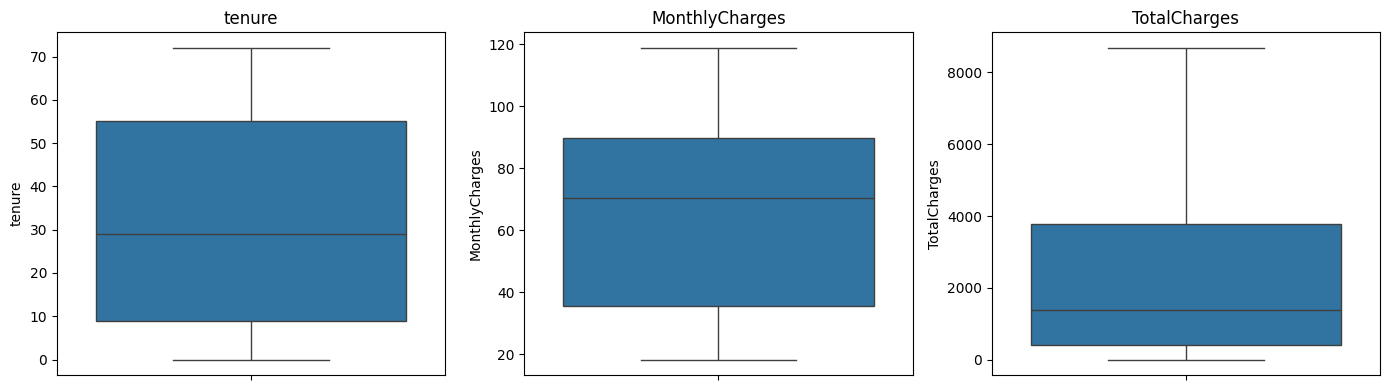

In [ ]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, numericas):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
for col in numericas:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    cant = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    print(f"{col}: Q1={q1:.2f}  Q3={q3:.2f}  límites=[{lim_inf:.2f}, {lim_sup:.2f}]  outliers={cant}")

tenure: Q1=9.00  Q3=55.00  límites=[-60.00, 124.00]  outliers=0
MonthlyCharges: Q1=35.50  Q3=89.85  límites=[-46.02, 171.38]  outliers=0
TotalCharges: Q1=398.55  Q3=3786.60  límites=[-4683.52, 8868.67]  outliers=0


No hay outliers en ninguna de las tres. TotalCharges tiene valores bastante altos (llega a más de
8000) pero no pasan el límite, y tiene sentido porque son clientes que hace muchos años que están.
Como son datos reales y no errores, no sacamos nada.

### 2.6 Guardar los datos limpios

In [ ]:
import os

os.makedirs("data/processed", exist_ok=True)
df.to_csv("data/processed/telco_limpio.csv", index=False)

print("guardado:", df.shape)
df.info()

guardado: (7043, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Gender            7043 non-null   object  
 1   SeniorCitizen     7043 non-null   object  
 2   Partner           7043 non-null   object  
 3   Dependents        7043 non-null   object  
 4   tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   object  
 6   MultipleLines     7043 non-null   object  
 7   InternetService   7043 non-null   object  
 8   OnlineSecurity    7043 non-null   object  
 9   OnlineBackup      7043 non-null   object  
 10  DeviceProtection  7043 non-null   object  
 11  TechSupport       7043 non-null   object  
 12  StreamingTV       7043 non-null   object  
 13  StreamingMovies   7043 non-null   object  
 14  Contract          7043 non-null   object  
 15  PaperlessBilling  7043 non-null   object  
 16  Pay

Quedaron 7043 filas y 24 columnas (sacamos customerID y agregamos 4). Ya no hay nulos y TotalCharges
es numérica.

## 3. Variables numéricas

### 3.1 Medidas de tendencia central y dispersión


In [ ]:
num = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


Con estos datos se puede interpretar lo siguiente sobre cada campo:
* **Antiguedad de cliente** (tenure)
  * **Promedio y dispersión**: En promedio podemos ver que los clientes llevan 32 meses en la empresa, pero una dispersión tan alta (casi 25) indica perfiles muy distintos entre clientes nuevos y antiguos
  * **Mín y Max**: En el mínimo y máximo podemos ver que existen clientes recién incorporados, por eso su tenure es de 0 meses, y clientes con hasta 72 meses de antiguedad
  * **Cuartiles**:
    * **Q1**: El 25% más nuevo de los clientes lleva 9 meses o menos como cliente
    * **Q2 (mediana)**: La mitad de los clientes tiene 29 meses o menos de antiguedad y la otra mitad tiene más
    * **Q3**: El 75% de los clientes tiene 55 meses o menos en la empresa
* **Cargo mensual** (MonthlyCarges)
  * **Promedio y dispersión**: En promedio el gasto mensual es de unos 64.76 dolares, con una variación de 30 dolares debido a los diferentes servicios contratados.
  * **Mín y Max**: La factura mensual más económica es de 18.25 dolares y la más alta llega a 118.75
  * **Cuartiles**:
    * **Q1**: El 25% de los clientes paga 35.50 dolares o menos por mes.
    * **Q2 (mediana)**: La mitad de los clientes paga menos de 70.35 dolares por mes y la otra mitad paga más. (Nota: al ser mayor que el promedio, indica que hay un grupo mucho más grande de gente que paga más que el promedio.)
    * **Q3**: El 75% de los clientes paga 89.85 o menos por mes
* **Cargo total acumulado** (TotalCharges)
  * **Promedio y dispersión**: En promedio el ingreso acumulado por cliente es de unos 2279.73 dolares y la dispersión es casi igual de grande (2266.79), esto se debe a la combinación de distintas antiguedades y tarifas
  * **Mín y Max**: El mínimo es 0 correspondiente a aquellos nuevos clientes que todavía no pagaron su primer factura y el máximo corresponde a los clientes con muchos años de antiguedad
  * **Cuartiles**:
    * **Q1**: El 25% de los clientes acumuló un gasto de 398.55 dolares o menos
    * **Q2 (mediana)**: La mitad de los clientes gastó en total 1394.55 dolares o menos
    * **Q3**: El 75% de los clientes acumuló 3786.60 dolares o menos



### 3.2 Comparación entre clientes que se fueron y los que se quedaron

In [ ]:
df.groupby("Churn")[num].agg(["mean", "median", "std"])


tenure                   MonthlyCharges                     \
            mean median        std           mean  median        std   
Churn                                                                  
No     37.569965   38.0  24.113777      61.265124  64.425  31.092648   
Yes    17.979133   10.0  19.531123      74.441332  79.650  24.666053   

      TotalCharges                         
              mean    median          std  
Churn                                      
No     2549.911442  1679.525  2329.954215  
Yes    1531.796094   703.550  1890.822994

**Antiguedad del cliente**: En promedio podemos ver que los clientes que se quedaron tienen más de 3 años en la empresa, mientras que por otro lado los clientes que abandonaron tienen un promedio de casi 18 meses y una mediana de 10 meses, es decir que la mitad de los que se fueron lo hicieron antes de los 10 meses. Esto apunta directamente hacia nuestra segunda hipótesis.

**Cargo mensual**: En promedio los clientes que se quedaron pagan 61.27 dolares al mes con una dispersión alta (31.09) indicando que existen clientes en planes económicos como costosos. Por otro lado, los clientes que se fueron pagan en promedio 74.44 dolares al mes con una dispersión menor (24.67). Esto apunta hacia nuestra tercera hipótesis ya que los que se dan de baja pagan una factura con un valor mucho más alto.

**Cargo total acumulado**: Por supuesto existe una diferencia enorme entre el promedio de los que se quedaron y los que se fueron ya que estos últimos no aportaron el suficiente tiempo en la empresa como para acumular un aporte mayor (en promedio 2549.90 dolares los que se quedaron contra 1531.80 los que se fueron)

### 3.3 Histogramas con KDE

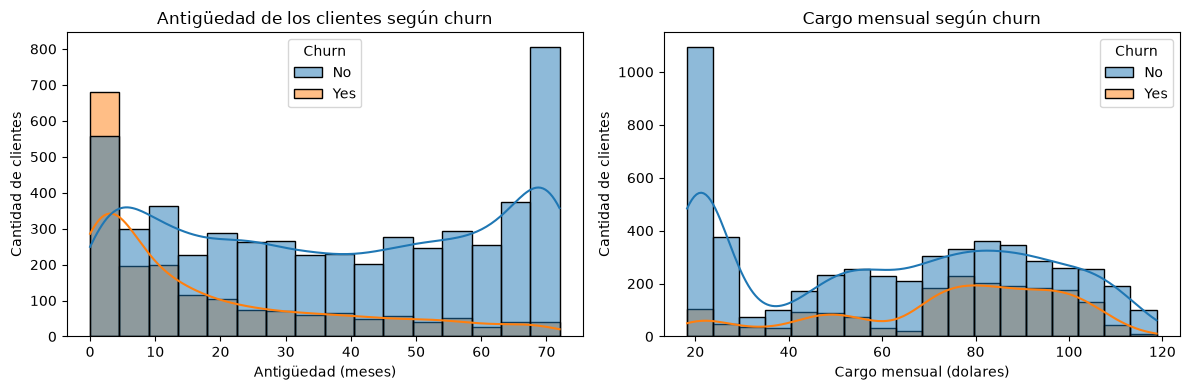

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, ax=axes[1])

axes[0].set_title("Antigüedad de los clientes según churn")
axes[0].set_xlabel("Antigüedad (meses)")
axes[0].set_ylabel("Cantidad de clientes")
axes[1].set_title("Cargo mensual según churn")
axes[1].set_xlabel("Cargo mensual (dolares)")
axes[1].set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

**Antiguedad del cliente**: Efectivamente podemos comprobar en el histograma que la baja de clientes se presenta en la etapa más temprana del tenure (entre 0 y 10 meses). A partir de ahí podemos ver como la línea naranja disminuye de forma constante indicando una mayor tasa de retención de clientes.

**Cargos mensuales**: En este gráfico podemos ver que la línea de churn arranca muy bajo indicando una menor cantidad de bajas de clientes pero esta va aumentando a medida que el valor mensual se va incrementando (entre los 70 y 100 dolares)

### 3.4 Correlación de Pearson y heatmap

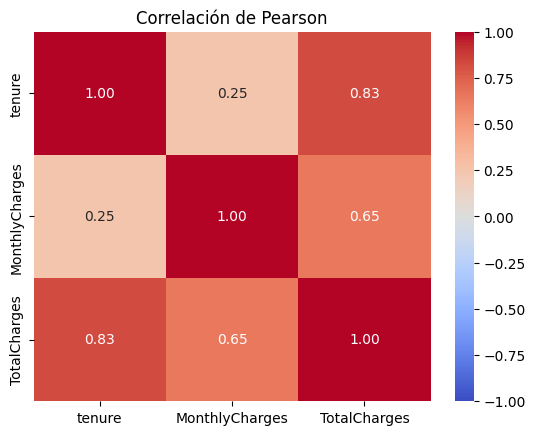

In [ ]:
corr = df[num].corr(method="pearson")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.show()

Con este gráfico podemos determinar lo siguiente:

* Existe una correlación positiva muy fuerte entre el tiempo de antiguedad (tenure) y el cargo total acumulado (total charges), con un valor de 0.83, y esto es lógico, ya que a mayor tiempo como cliente, mayor es el monto total que acumuló en sus pagos.

* Se puede observar que hay una correlación positiva moderada entre los cargos mensuales (monthlyCharge) y el total acumulado (totalCharges), de 0.65, ya que los que tienden a pagar facturas más caras tienden a acumular un monto total mayor con el paso del tiempo.

* Existe una correlación positiva débil entre el tiempo de antiguedad (tenure) y los cargos mensuales (monthlyCharges), de solo 0.25, indicando que casi no existe una relación porque tenemos clientes nuevos con planes caros y clientes antiguos con planes baratos.

* Igual hay que tener en cuenta que correlación no significa causa: que dos variables se muevan juntas no quiere decir que una provoque la otra.

## 4. Variables categóricas

### 4.1 Frecuencias

Primero vemos cuántos clientes hay en cada categoría (frecuencia absoluta) y qué porcentaje del total
son (frecuencia relativa). Miramos variables de los clientes (género, edad, pareja, hijos) y del
contrato (internet, tipo de contrato, forma de pago, factura).

In [ ]:
variables = ["Gender", "SeniorCitizen", "Partner", "Dependents",
             "InternetService", "Contract", "PaymentMethod", "PaperlessBilling"]

for col in variables:
    frecuencias = pd.DataFrame({
        "cantidad": df[col].value_counts(),
        "porcentaje": (df[col].value_counts(normalize=True) * 100).round(1),
    })
    print(frecuencias)
    print()

        cantidad  porcentaje
Gender                      
Male        3555        50.5
Female      3488        49.5

               cantidad  porcentaje
SeniorCitizen                      
No                 5901        83.8
Yes                1142        16.2

         cantidad  porcentaje
Partner                      
No           3641        51.7
Yes          3402        48.3

            cantidad  porcentaje
Dependents                      
No              4933        70.0
Yes             2110        30.0

                 cantidad  porcentaje
InternetService                      
Fiber optic          3096        44.0
DSL                  2421        34.4
No                   1526        21.7

                cantidad  porcentaje
Contract                            
Month-to-month      3875        55.0
Two year            1695        24.1
One year            1473        20.9

                           cantidad  porcentaje
PaymentMethod                                  
Electronic 

- Hay casi la misma cantidad de hombres y mujeres (50.5% y 49.5%).
- Solo el 16% son adultos mayores y el 30% tiene personas a cargo.
- Más de la mitad de los clientes (55%) tiene contrato mes a mes, o sea que se pueden ir cuando quieran.
- La fibra óptica es el internet más usado (44%).
- La forma de pago más común es el cheque electrónico (33.6%).

### 4.2 Tablas de contingencia

Cruzamos las variables con Churn. Primero en cantidades, con los totales (`margins=True`):

In [ ]:
pd.crosstab(df["Contract"], df["Churn"], margins=True)

Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


Como los grupos tienen distinto tamaño (hay muchos más clientes mes a mes que de 2 años), es mejor
comparar porcentajes. Con `normalize="index"` cada fila suma 100%, así vemos qué porcentaje de cada
grupo se dio de baja:

In [ ]:
(pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100).round(1)

Churn,No,Yes
Contract,,
Month-to-month,57.3,42.7
One year,88.7,11.3
Two year,97.2,2.8


In [ ]:
(pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100).round(1)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.8,15.2
Electronic check,54.7,45.3
Mailed check,80.9,19.1


Lo mismo para el resto de las variables:

In [ ]:
for col in ["Gender", "SeniorCitizen", "Partner", "Dependents", "InternetService", "PaperlessBilling"]:
    print((pd.crosstab(df[col], df["Churn"], normalize="index") * 100).round(1))
    print()

Churn     No   Yes
Gender            
Female  73.1  26.9
Male    73.8  26.2

Churn            No   Yes
SeniorCitizen            
No             76.4  23.6
Yes            58.3  41.7

Churn      No   Yes
Partner            
No       67.0  33.0
Yes      80.3  19.7

Churn         No   Yes
Dependents            
No          68.7  31.3
Yes         84.5  15.5

Churn              No   Yes
InternetService            
DSL              81.0  19.0
Fiber optic      58.1  41.9
No               92.6   7.4

Churn               No   Yes
PaperlessBilling            
No                83.7  16.3
Yes               66.4  33.6



- **Género:** no cambia nada, se van igual hombres y mujeres (26.9% y 26.2%).
- **Adultos mayores:** se van mucho más (41.7% contra 23.6% del resto).
- **Pareja y personas a cargo:** los que no tienen se van más (33% sin pareja contra 19.7% con pareja,
  y 31.3% sin personas a cargo contra 15.5%).
- **Internet:** los de fibra óptica se van mucho más (41.9%) que los de DSL (19%) y los que no tienen
  internet (7.4%).
- **Factura electrónica:** los que la tienen se van el doble (33.6% contra 16.3%).

### 4.3 Porcentaje de bajas por contrato y por forma de pago

Para sacar el porcentaje de bajas de cada grupo usamos ChurnNum: como vale 1 si se fue y 0 si no,
su promedio es directamente la proporción de bajas.

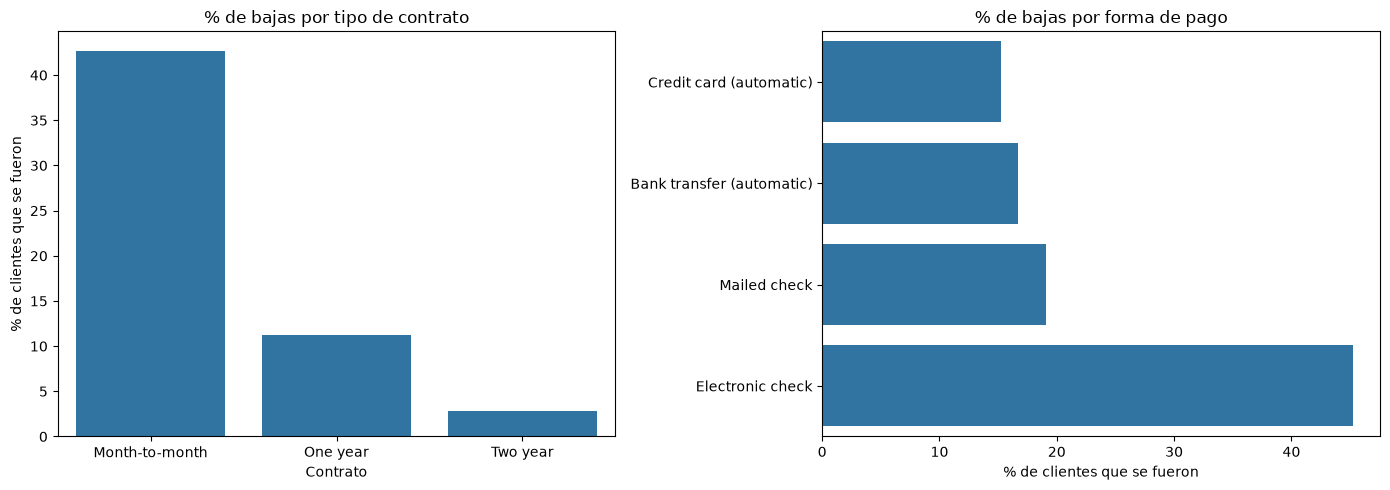

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tasa_contrato = df.groupby("Contract")["ChurnNum"].mean() * 100
tasa_contrato = tasa_contrato.loc[["Month-to-month", "One year", "Two year"]]
sns.barplot(x=tasa_contrato.index, y=tasa_contrato.values, ax=axes[0])
axes[0].set_title("% de bajas por tipo de contrato")
axes[0].set_xlabel("Contrato")
axes[0].set_ylabel("% de clientes que se fueron")

tasa_pago = (df.groupby("PaymentMethod")["ChurnNum"].mean() * 100).sort_values()
sns.barplot(x=tasa_pago.values, y=tasa_pago.index, ax=axes[1])
axes[1].set_title("% de bajas por forma de pago")
axes[1].set_xlabel("% de clientes que se fueron")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Contrato (H1):** se cumple. De los clientes mes a mes se fue el 42.7%, de los de 1 año el 11.3% y de
los de 2 años solo el 2.8%. Es la diferencia más grande de todo el análisis. Para la empresa, pasar
clientes de mes a mes a contratos más largos es lo que más bajas evitaría.

**Forma de pago (H4):** se cumple. Los que pagan con cheque electrónico se van un 45.3%, casi el triple
que los que tienen débito automático o tarjeta (15-17%). El cheque por correo (19.1%) está más cerca de
los automáticos, así que el problema es puntualmente el cheque electrónico.

### 4.4 Antigüedad, cargo mensual e internet

Para ver también la H2 y la H3 por grupos, usamos GrupoAntiguedad (que creamos en la limpieza) y
dividimos el cargo mensual en rangos. Además miramos el internet junto con el soporte técnico.

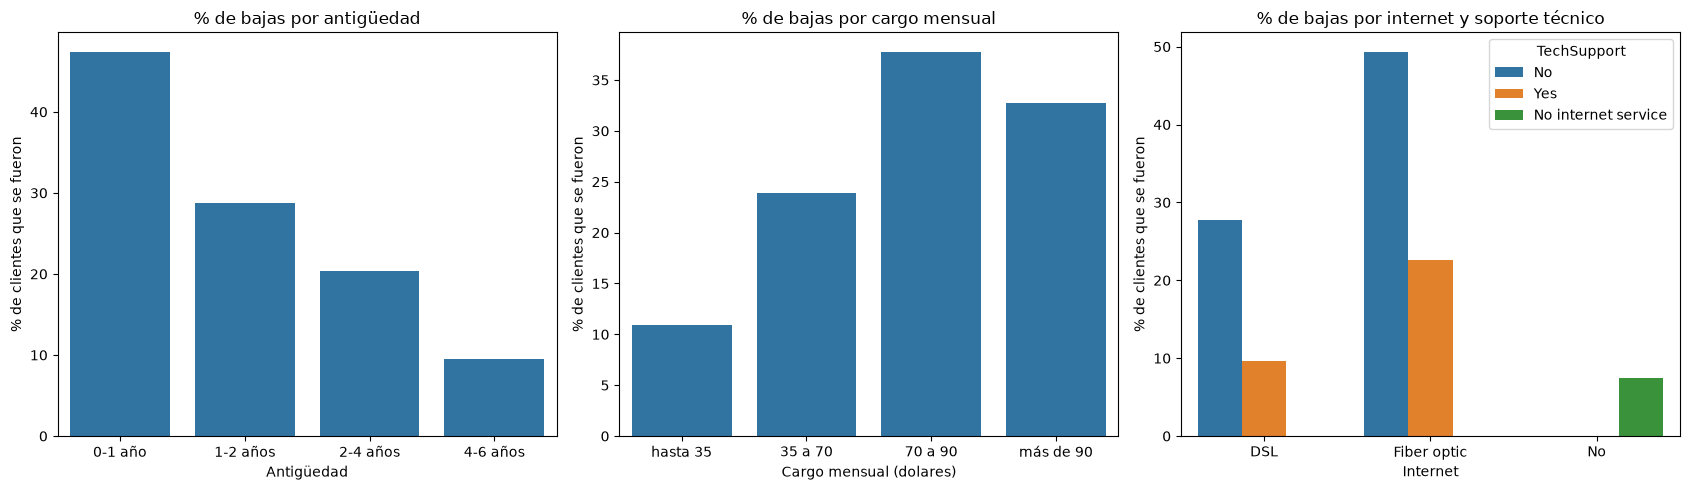

In [ ]:
rango_cargo = pd.cut(df["MonthlyCharges"], bins=[0, 35, 70, 90, 120],
                     labels=["hasta 35", "35 a 70", "70 a 90", "más de 90"])

tasa_antiguedad = df.groupby("GrupoAntiguedad", observed=True)["ChurnNum"].mean() * 100
tasa_cargo = df.groupby(rango_cargo, observed=True)["ChurnNum"].mean() * 100
tasa_internet = (df.groupby(["InternetService", "TechSupport"])["ChurnNum"].mean() * 100).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(x=tasa_antiguedad.index, y=tasa_antiguedad.values, ax=axes[0])
axes[0].set_title("% de bajas por antigüedad")
axes[0].set_xlabel("Antigüedad")
axes[0].set_ylabel("% de clientes que se fueron")

sns.barplot(x=tasa_cargo.index, y=tasa_cargo.values, ax=axes[1])
axes[1].set_title("% de bajas por cargo mensual")
axes[1].set_xlabel("Cargo mensual (dolares)")
axes[1].set_ylabel("% de clientes que se fueron")

sns.barplot(data=tasa_internet, x="InternetService", y="ChurnNum", hue="TechSupport", ax=axes[2])
axes[2].set_title("% de bajas por internet y soporte técnico")
axes[2].set_xlabel("Internet")
axes[2].set_ylabel("% de clientes que se fueron")

plt.tight_layout()
plt.show()

**Antigüedad (H2):** se cumple. En el primer año se va el 47.4% de los clientes, y después baja cada
vez más hasta el 9.5% en los que llevan entre 4 y 6 años. El primer año es el momento más crítico.

**Cargo mensual (H3):** se cumple en general. Los que pagan hasta 35 dolares casi no se van (10.9%),
y a partir de ahí sube: 23.9% entre 35 y 70 y 37.8% entre 70 y 90. En los de más de 90 baja un poco
(32.8%), pero sigue siendo alto.

**Internet y soporte técnico:** la fibra óptica sin soporte técnico es el peor caso (49.4% de bajas).
Con soporte técnico baja a 22.6%. Con DSL pasa lo mismo (27.8% sin soporte contra 9.7% con soporte).
O sea que el soporte técnico ayuda mucho a que los clientes se queden.

## 5. Segmentación y conclusiones

Clientes  Bajas  Tasa_Churn_Pct  \
Contract       InternetService                                    
Month-to-month Fiber optic          2128   1162            54.6   
               DSL                  1223    394            32.2   
One year       Fiber optic           539    104            19.3   
Month-to-month No                    524     99            18.9   
One year       DSL                   570     53             9.3   
Two year       Fiber optic           429     31             7.2   
One year       No                    364      9             2.5   
Two year       DSL                   628     12             1.9   
               No                    638      5             0.8   

                                Cargo_Mensual_Prom  
Contract       InternetService                      
Month-to-month Fiber optic                    87.0  
               DSL                            50.2  
One year       Fiber optic                    98.8  
Month-to-month No                             20.4  
One year       DSL                            61.4  
Two year       Fiber optic                   104.6  
One year       No                             20.8  
Two year       DSL                            70.5  
               No                             21.8

Perfil Alto Riesgo (Mes a mes & Fibra óptica & <=12 meses): 916 clientes | Bajas: 643 (70.2%)
Perfil Bajo Riesgo (Contrato 1-2 años | Antigüedad >48 meses): 3510 clientes | Bajas: 303 (8.6%)
Ingreso mensual perdido total (1.869 bajas): $139,130.85
Proyección de pérdida anualizada total: $1,669,570.20
Ingreso mensual perdido solo en el perfil de Alto Riesgo: $53,178.30 (38.2% del total perdido)


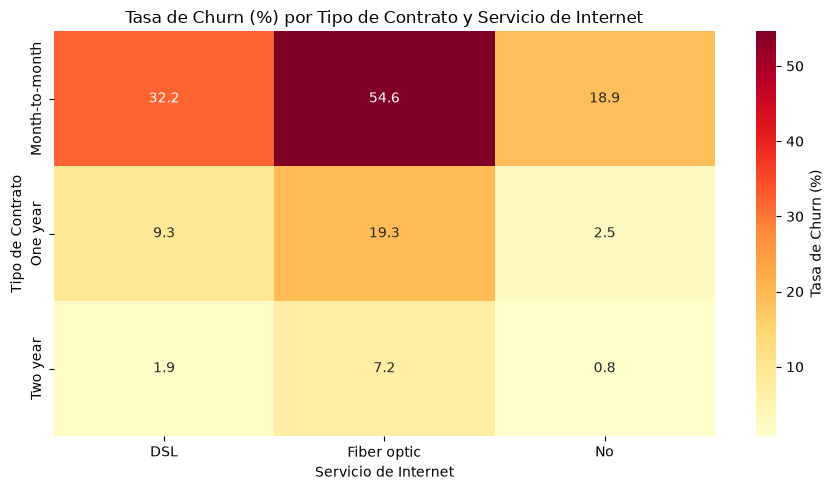

In [ ]:
if "ChurnNum" not in df.columns:
  df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)

segmentos = (
    df.groupby(["Contract", "InternetService"], observed=False)
    .agg(
        Clientes=("ChurnNum", "count"),
        Bajas=("ChurnNum", "sum"),
        Tasa_Churn_Pct=("ChurnNum", lambda s: round(s.mean() * 100, 1)),
        Cargo_Mensual_Prom=("MonthlyCharges", lambda s: round(s.mean(), 1)),
    )
    .sort_values(by="Tasa_Churn_Pct", ascending=False)
)

display(segmentos)

cond_alto_riesgo = (
    (df["Contract"] == "Month-to-month")
    & (df["InternetService"] == "Fiber optic")
    & (df["tenure"] <= 12)
)

cond_bajo_riesgo = (
    (df["Contract"].isin(["One year", "Two year"]))
    | (df["tenure"] > 48)
)

alto_riesgo = df[cond_alto_riesgo]
bajo_riesgo = df[cond_bajo_riesgo]
clientes_perdidos = df[df["Churn"] == "Yes"]

ingreso_mensual_perdido = clientes_perdidos["MonthlyCharges"].sum()
ingreso_anual_perdido = ingreso_mensual_perdido * 12
ingreso_mensual_alto_riesgo = alto_riesgo[alto_riesgo["Churn"] == "Yes"]["MonthlyCharges"].sum()

print(
    f"Perfil Alto Riesgo (Mes a mes & Fibra óptica & <=12 meses): "
    f"{len(alto_riesgo)} clientes | Bajas: {alto_riesgo['ChurnNum'].sum()} "
    f"({alto_riesgo['ChurnNum'].mean() * 100:.1f}%)"
)
print(
    f"Perfil Bajo Riesgo (Contrato 1-2 años | Antigüedad >48 meses): "
    f"{len(bajo_riesgo)} clientes | Bajas: {bajo_riesgo['ChurnNum'].sum()} "
    f"({bajo_riesgo['ChurnNum'].mean() * 100:.1f}%)"
)

print(f"Ingreso mensual perdido total (1.869 bajas): ${ingreso_mensual_perdido:,.2f}")
print(f"Proyección de pérdida anualizada total: ${ingreso_anual_perdido:,.2f}")
print(
    f"Ingreso mensual perdido solo en el perfil de Alto Riesgo: "
    f"${ingreso_mensual_alto_riesgo:,.2f} ({ingreso_mensual_alto_riesgo / ingreso_mensual_perdido * 100:.1f}% del total perdido)"
)

pivot_churn = df.pivot_table(
    index="Contract",
    columns="InternetService",
    values="ChurnNum",
    aggfunc=lambda s: s.mean() * 100,
)
orden_contrato = [
    c for c in ["Month-to-month", "One year", "Two year"] if c in pivot_churn.index
]
pivot_churn = pivot_churn.loc[orden_contrato]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    pivot_churn,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Tasa de Churn (%)"},
    ax=ax,
)
ax.set_title(
    "Tasa de Churn (%) por Tipo de Contrato y Servicio de Internet",
)
ax.set_xlabel("Servicio de Internet")
ax.set_ylabel("Tipo de Contrato")
plt.tight_layout()
plt.show()

### 5.1 Segmentación de clientes según riesgo de baja

Sobre una base de **7.043 clientes**, la tasa general de abandono (*Churn*) es del **26.5%** (**1.869 bajas**). Aplicando filtros combinados sobre las variables mas influyentes, se definen tres segmentos:

**Riesgo alto (perfil crítico combinado)**: Clientes que cumplen simultáneamente (`&`) tener contrato mes a mes (Month-to-month), servicio de fibra óptica (`Fiber optic`) y una antigüedad menor o igual a 12 meses (`tenure <= 12`). Este grupo concentra 916 clientes, de los cuales 643 se dieron de baja, alcanzando una tasa de abandono del 70.2% (muy por encima del **54.6%** que se observa al cruzar solo contrato mes a mes y fibra óptica sin filtrar antigüedad). Además, factores como el pago con cheque electrónico (**45.3%**) o la ausencia de *TechSupport* actúan como agravantes dentro de este grupo.

**Riesgo medio**: Clientes que no pertenecen al núcleo crítico anterior, generalmente con antigüedad intermedia (**1 a 4 años**), contratos mes a mes con servicio DSL o sin internet, o bien contratos de 1 año (`One year`, **11.3% de baja**), donde el abandono disminuye drásticamente frente al segmento de riesgo alto.

**Riesgo bajo**: Clientes filtrados mediante la condición alternativa (`|`) de poseer un contrato a plazo fijo (`One year` o `Two year`) o contar con una antigüedad superior a 4 años (`tenure > 48`). Este segmento agrupa a 3.510 clientes con una tasa de baja de apenas 8.6% (y solo 2.8% en contratos de 2 años), apoyado además en pagos automáticos (**~15%–17%**) y mayor cantidad de servicios contratados.

### 5.2 Validación de hipótesis

* **H1 (Contrato mes a mes vs. 1 o 2 años):** **Confirmada.** Los contratos `Month-to-month` registran **42.7%** de baja, frente a **11.3%** en `One year` y **2.8%** en `Two year`.
* **H2 (Clientes nuevos vs. antiguos):** **Confirmada.** Los clientes de `0-1 año` presentan **47.4%** de tasa de *Churn*, mientras que en `4-6 años` cae a **9.5%** (y la mediana de antigüedad de quienes se van es de **10 meses** frente a **38 meses** en quienes permanecen).
* **H3 (Mayor cargo mensual = mayor baja):** **Se cumple en general.** Si bien quienes se dan de baja tienen un cargo mensual promedio mayor (**USD 74.44**) que quienes continúan (**USD 61.27**), el aumento del *Churn* no responde únicamente al precio aislado, sino a su interacción con el tipo de servicio y contrato: los cargos altos se concentran en clientes con fibra óptica que, al no tener compromiso de permanencia ni soporte técnico, abandonan en mayor proporción. En cambio, los clientes con cargos altos y contratos largos retienen tasas bajas de abandono.
* **H4 (Cheque vs. débito automático):** **Confirmada.** El pago con `Electronic check` alcanza **45.3%** de baja, muy por encima de la transferencia bancaria automática (**16.7%**) y la tarjeta de crédito automática (**15.2%**).

### 5.3 Conclusiones y posibles acciones

El abandono no solo representa una pérdida de clientes, sino un impacto financiero directo significativo: las 1.869 bajas implican una pérdida de **USD 139,130.85** en ingresos mensuales, equivalente a **USD 1,669,570.20** anualizados. Más aún, el perfil de riesgo alto definido (`Month-to-month` & `Fiber optic` & `tenure <= 12`) explica por sí solo **USD 53,178.30** mensuales (38.2% de todo el dinero perdido por Churn en la compañía).

Para reducir esta fuga de ingresos, se proponen tres líneas de acción prioritarias:

1. **Programa de retención temprana en el primer año:** Focalizar campañas de seguimiento, onboarding y beneficios escalonados durante los primeros 12 meses en clientes nuevos de fibra óptica, donde se concentra casi el 40% de la pérdida económica.

2. **Migración incentivada a contratos anuales:** Ofrecer descuentos promocionales o meses bonificados para convertir clientes Month-to-month a planes de One year, atacando el salto más fuerte de caída en la tasa de abandono (del 42.7% al 11.3%).

3. **Revisión de la propuesta de valor en Fibra Óptica y medios de pago:** Incluir paquetes bonificados de TechSupport y OnlineSecurity en los planes de fibra óptica para justificar el cargo mensual, e incentivar la adhesión al débito automático frente al cheque electrónico.